# 03. Análise de Faturamento e Vendas por Mês

Este notebook analisa a evolução temporal das vendas e do faturamento da loja de informática ao longo dos meses.

- **Pipeline Utilizado:** Módulo `excel_to_pandas_analytics.tratamento` (`tratar_dados` / `aplicar_pipeline_tratamento`).
- **Ordenação Cronológica:** Garantida pela categorização ordenada dos meses, evitando a ordenação alfabética padrão do `.groupby()`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importa funções do pacote estruturado em src
from excel_to_pandas_analytics import carregar_dados_loja, tratar_dados

# 1. Carrega os dados brutos e aplica o pipeline de tratamento
df_bruto = carregar_dados_loja()
df = tratar_dados(df_bruto)

# Visualiza uma amostra dos dados tratados
df[['ID Transação', 'Data', 'Mês', 'Produto', 'Preço Unitário (R$)', 'Qtd Vendida', 'Faturamento Total (R$)', 'Status Estoque']].head()

,ID Transação,Data,Mês,Produto,Preço Unitário (R$),Qtd Vendida,Faturamento Total (R$),Status Estoque
0,TR1001,2026-02-27,Fevereiro,Notebook Gamer i7 16GB,4608.70,4,18434.80,Normal
1,TR1002,2026-03-13,Março,Fonte 600W 80 Plus,384.10,12,4609.20,Normal
2,TR1003,2026-02-14,Fevereiro,Headset Gamer 7.1,277.81,1,277.81,Baixo
3,TR1004,2026-04-22,Abril,Processador Ryzen 7 5700X,1400.75,1,1400.75,Normal
4,TR1005,2026-04-12,Abril,Fonte 600W 80 Plus,406.00,9,3654.00,Normal


## Agrupamento e Métricas Mensais

Agrupamento por mês calculando:
1. **Faturamento Total (R$):** soma da receita mensal
2. **Qtd Vendida:** quantidade total de itens vendidos no mês
3. **Total Transações:** quantidade de vendas/pedidos realizados

In [2]:
# 2. Agrupamento mensal respeitando a ordenação cronológica
vendas_por_mes = (
    df.groupby('Mês', observed=True)
    .agg({
        'Faturamento Total (R$)': 'sum',
        'Qtd Vendida': 'sum',
        'ID Transação': 'count',
    })
    .rename(columns={'ID Transação': 'Total Transações'})
    .reset_index()
)

print("=== Resumo Mensal de Vendas e Faturamento ===")
vendas_por_mes.style.format({
    'Faturamento Total (R$)': 'R$ {:,.2f}',
    'Qtd Vendida': '{:,.0f}',
    'Total Transações': '{:,.0f}',
})

=== Resumo Mensal de Vendas e Faturamento ===


,Mês,Faturamento Total (R$),Qtd Vendida,Total Transações
0,Janeiro,"R$ 281,850.52",276,34
1,Fevereiro,"R$ 453,051.13",426,53
2,Março,"R$ 560,076.64",451,55
3,Abril,"R$ 393,395.23",351,42
4,Maio,"R$ 557,005.45",387,51
5,Junho,"R$ 369,262.46",491,58
6,Julho,"R$ 284,581.50",318,38
7,Agosto,"R$ 590,913.92",464,57
8,Setembro,"R$ 515,299.33",463,54
9,Outubro,"R$ 507,487.36",376,50


## Visualização Gráfica do Desempenho Mensal

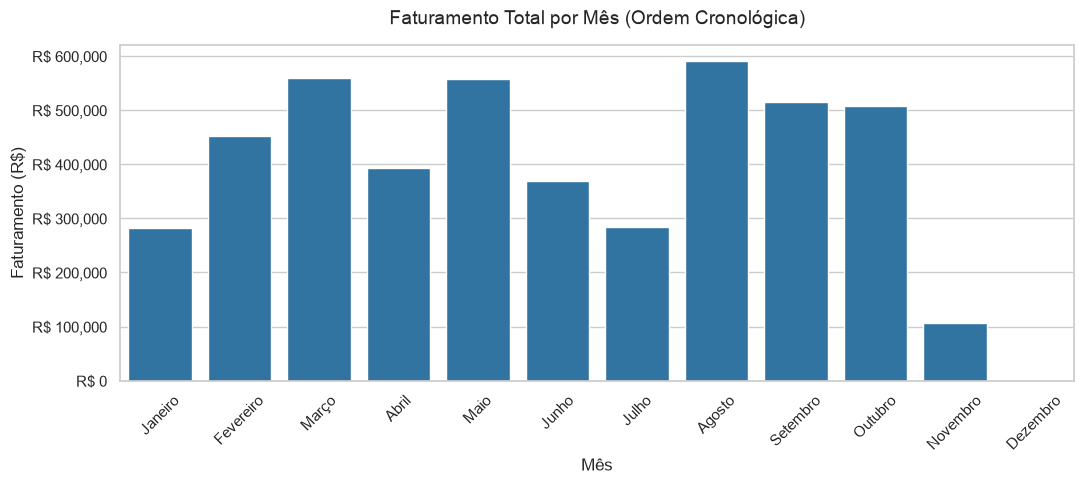

In [3]:
plt.figure(figsize=(11, 5))
sns.set_theme(style="whitegrid")

grafico = sns.barplot(
    data=vendas_por_mes,
    x='Mês',
    y='Faturamento Total (R$)',
    color='#1f77b4'
)

plt.title('Faturamento Total por Mês (Ordem Cronológica)', fontsize=14, pad=15)
plt.xlabel('Mês', fontsize=12)
plt.ylabel('Faturamento (R$)', fontsize=12)
plt.xticks(rotation=45)

# Formatação monetária no eixo Y
grafico.yaxis.set_major_formatter('R$ {x:,.0f}')

plt.tight_layout()
plt.show()